# Proyecto final «Agente Inversor»
**Simulación y Aprendizaje por Refuerzo · MIA 2026-5 · Universidad de La Sabana**
Actividad calificable 4 (30 %) · Profesor: Emilio Muñoz

| Integrante (GitHub) | Función | Verifica a |
|---|---|---|
| Diego Ríos (`dialrigo`) | Integración, corrida oficial, presentación y entrega | Todos (checklist final) |
| Andrés Díaz (`andresdila`) | Datos, EDA y formulación (secc. 2–3) | Nicolás |
| Nicolás Gamboa (`JnicolasGh`) | Entorno y pruebas automáticas (secc. 4) | janayajoo |
| `janayajoo` | Diseño e iteración de la recompensa (secc. 5–6) | Lorena |
| Lorena Valero (`LorenaValero20`) | Evaluación held-out, baselines y anomalía (secc. 8–9) | Marlon |
| Marlon Umbarila (`Marlon-Umbarila`) | Algoritmo, Optuna, semillas y reproducibilidad (secc. 7 y 12) | Nataly |
| Nataly Valbuena (`natavalbuenal`) | Discusión, referencias e informe (secc. 10–11) | Andrés |

**Pregunta central:** ¿puede un agente de RL aprender una estrategia de inversión que se comporte mejor que comprar y mantener o que un agente aleatorio, en un periodo que nunca vio?

**Cómo está organizado el código.** Partimos del repositorio base del curso (`rl_games_sb`, Stable-Baselines3 + MLflow + Optuna). Lo nuevo está en tres módulos pequeños:

| Archivo | Qué hace |
|---|---|
| `src/rl_games_sb/investor_data.py` | Precios de GOOGL, indicadores y división temporal train / val / test |
| `src/rl_games_sb/investor_env.py` | El entorno Gymnasium: posición, costos, recompensa |
| `src/rl_games_sb/investor_eval.py` | Baselines y métricas (retorno, drawdown, costos) |
| `configs/investor_dqn_*.yaml` | Hiperparámetros de DQN para cada versión de la recompensa |

Este notebook solo orquesta: llama a esos módulos, muestra resultados e interpreta.

## 1. Configuración y semillas
Kernel: el `.venv` del proyecto (ver `CONFIGURACION_KERNEL.md`). Todas las corridas usan la semilla 42.
`RETRAIN = True` borra los modelos guardados y entrena desde cero; con `False` reutiliza los de `saves/`.

In [1]:
import os
from pathlib import Path

# El notebook vive en notebooks/; trabajamos desde la raíz del proyecto para que
# saves/, results/ y mlflow.db queden en un solo lugar.
if Path.cwd().name == "notebooks":
    os.chdir("..")
ROOT = Path.cwd()
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)

import random

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import torch

from rl_games_sb import (
    config,
    envs,
    experiments,
    investor_data,
    investor_eval,
    registry,
)
from rl_games_sb.investor_env import ACTIONS, InvestorEnv

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

RETRAIN = True      # False: reutiliza saves/*.zip si ya existen
RUN_TUNE = False    # True: búsqueda Optuna (≈15 trials, tarda bastante más)
RUN_SEEDS = False   # True: reentrena la versión final con 3 semillas extra

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"RL v1 (simple)": "#2a6fdb", "RL v2 (log + drawdown)": "#e8590c",
          "Comprar y mantener": "#2b8a3e", "Aleatorio": "#868e96"}

print("Raíz del proyecto:", ROOT)
print("torch", torch.__version__, "| CUDA disponible:", torch.cuda.is_available())

c:\Users\diego\Documents\003 EFMIA\agente-inversor\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Raíz del proyecto: c:\Users\diego\Documents\003 EFMIA\agente-inversor
torch 2.14.1+cu130 | CUDA disponible: True


## 2. Datos y análisis exploratorio
Usamos el dataset común del curso: los precios diarios de **GOOGL** que trae `gym-anytrading` (2009-05-22 a 2018-08-29, ya ajustados por el split de 2014). Columnas: `Open, High, Low, Close, Adj Close, Volume`; usamos `Close` y `Volume`.

**División temporal** (nunca aleatoria):

| Periodo | Fechas | Uso |
|---|---|---|
| Entrenamiento | 2009 – 2015 | El agente aprende |
| Validación | 2016 | Comparar recompensas y elegir hiperparámetros |
| Held-out (prueba) | 2017 – 2018-08 | Evaluación final, **una sola vez** |

In [2]:
prices = investor_data.load_prices()
table = investor_data.add_features(prices)
# El EDA usa solo train y validación: el held-out (2017-2018) se describe recién en la sección 8.
eda = prices[prices.index <= investor_data.VAL_END]

splits = {name: investor_data.get_split(name) for name in ("train", "val", "test")}


def fila(name, p, d):
    base = {"desde": d[0].date(), "hasta": d[-1].date(), "días": len(d)}
    if name == "test":  # del held-out solo mostramos fechas y tamaño
        return base
    return base | {"precio inicial": round(p[0], 2), "precio final": round(p[-1], 2),
                   "retorno del activo %": round(100 * (p[-1] / p[0] - 1), 1)}


resumen = pd.DataFrame({name: fila(name, p, d) for name, (p, _, d) in splits.items()}).T.fillna("—")
resumen

,desde,hasta,días,precio inicial,precio final,retorno del activo %
train,2009-08-03,2015-12-31,1616,226.33,778.01,243.7
val,2016-01-04,2016-12-30,252,759.44,792.45,4.3
test,2017-01-03,2018-08-29,418,—,—,—


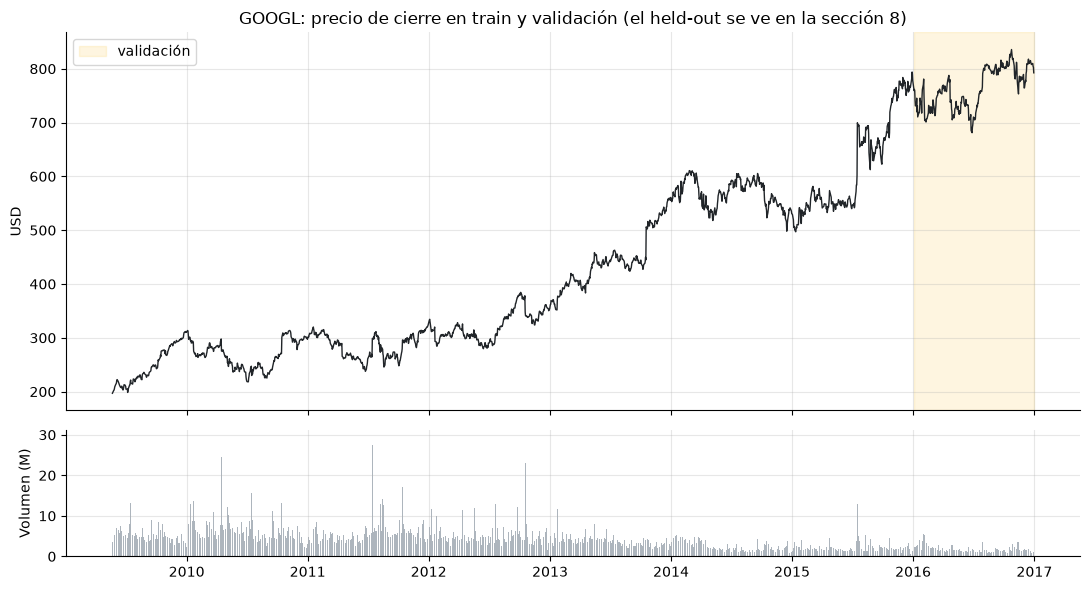

In [3]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax[0].plot(eda.index, eda["Close"], color="#212529", lw=1)
d = splits["val"][2]
ax[0].axvspan(d[0], d[-1], color="#fab005", alpha=0.12, label="validación")
ax[0].set_title("GOOGL: precio de cierre en train y validación (el held-out se ve en la sección 8)")
ax[0].set_ylabel("USD")
ax[0].legend(loc="upper left")
ax[1].bar(eda.index, eda["Volume"] / 1e6, color="#adb5bd", width=1)
ax[1].set_ylabel("Volumen (M)")
fig.tight_layout()
fig.savefig(RESULTS / "01_precio_periodos.png", dpi=150)

,retornos log diarios
media diaria %,0.073
desv. diaria %,1.535
asimetría,0.744
curtosis (exceso),12.882
peor día %,-8.749
mejor día %,15.065


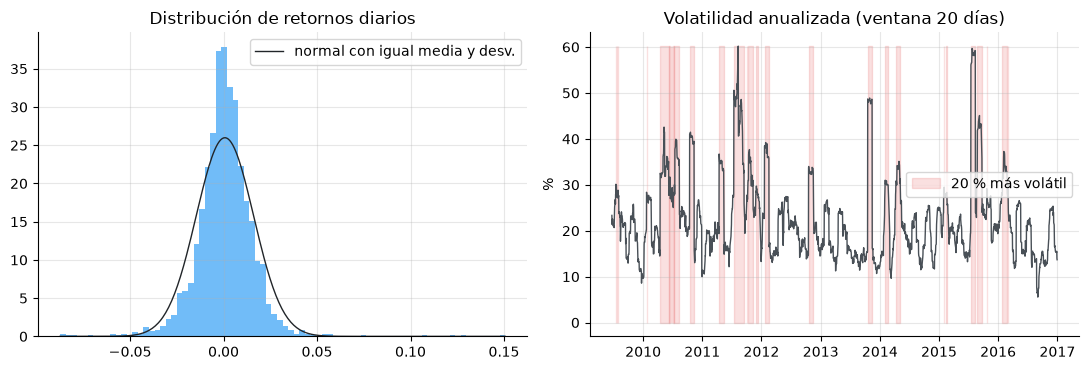

In [4]:
r = np.log(eda["Close"]).diff().dropna()
stats = pd.Series({"media diaria %": 100 * r.mean(), "desv. diaria %": 100 * r.std(),
                   "asimetría": r.skew(), "curtosis (exceso)": r.kurt(),
                   "peor día %": 100 * r.min(), "mejor día %": 100 * r.max()}).round(3)
display(stats.to_frame("retornos log diarios"))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(r, bins=80, density=True, color="#4dabf7", alpha=0.8)
x = np.linspace(r.min(), r.max(), 300)
ax[0].plot(x, np.exp(-0.5 * ((x - r.mean()) / r.std())**2) / (r.std() * np.sqrt(2 * np.pi)),
           color="#212529", lw=1, label="normal con igual media y desv.")
ax[0].set_title("Distribución de retornos diarios")
ax[0].legend()
vol = r.rolling(20).std() * np.sqrt(252) * 100
alta = vol > vol.quantile(0.8)
ax[1].plot(vol.index, vol, color="#495057", lw=1)
ax[1].fill_between(vol.index, 0, vol.max(), where=alta, color="#e03131", alpha=0.15, label="20 % más volátil")
ax[1].set_title("Volatilidad anualizada (ventana 20 días)")
ax[1].set_ylabel("%")
ax[1].legend()
fig.tight_layout()
fig.savefig(RESULTS / "02_retornos_volatilidad.png", dpi=150)

,desde,mínimo,caída máx %,recuperado
21,2010-01-05,2010-07-06,30.4,2010-11-08
23,2011-01-19,2011-06-24,25.8,2011-12-27
60,2014-02-27,2015-01-12,18.6,2015-07-17


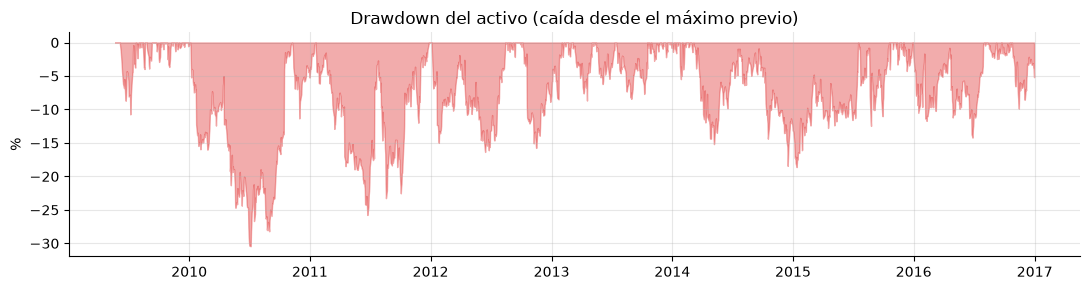

In [5]:
# Caídas (drawdown) del activo: la referencia de riesgo de comprar y mantener.
dd = 100 * (1 - eda["Close"] / eda["Close"].cummax())
fig, ax = plt.subplots(figsize=(11, 3))
ax.fill_between(dd.index, 0, -dd, color="#e03131", alpha=0.4)
ax.set_title("Drawdown del activo (caída desde el máximo previo)")
ax.set_ylabel("%")
fig.tight_layout()
fig.savefig(RESULTS / "03_drawdown_activo.png", dpi=150)

# Las 3 peores caídas, con su fecha de máximo y de mínimo
episodios, en_caida, inicio = [], False, None
for fecha, v in dd.items():
    if v > 0 and not en_caida:
        en_caida, inicio = True, fecha
    if v == 0 and en_caida:
        tramo = dd.loc[inicio:fecha]
        episodios.append({"desde": inicio.date(), "mínimo": tramo.idxmax().date(),
                          "caída máx %": round(tramo.max(), 1), "recuperado": fecha.date()})
        en_caida = False
pd.DataFrame(episodios).sort_values("caída máx %", ascending=False).head(3)

,mean,std,min,max
ret_1,0.0008,0.0157,-0.0875,0.1506
ret_5,0.0039,0.0358,-0.1384,0.2296
ret_20,0.0158,0.0699,-0.2306,0.2650
dist_sma20,0.0078,0.0393,-0.1417,0.2381
dist_sma50,0.0204,0.0616,-0.1299,0.2602
vol_20,0.0146,0.0060,0.0054,0.0379
rsi_14,54.2747,17.4643,4.4993,95.4155


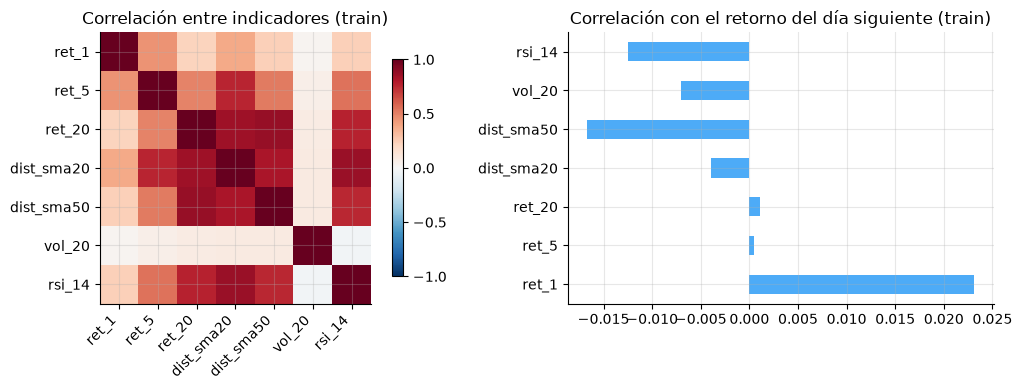

In [6]:
# Indicadores: solo sobre ENTRENAMIENTO, para no mirar validación ni prueba.
feats = list(investor_data.FEATURES)
train = table[table.index <= investor_data.TRAIN_END].copy()
train["ret_siguiente"] = np.log(train["Close"]).diff().shift(-1)  # solo para este análisis

display(train[feats].describe().T[["mean", "std", "min", "max"]].round(4))
corr = train[feats + ["ret_siguiente"]].corr()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
im = ax[0].imshow(corr.loc[feats, feats], cmap="RdBu_r", vmin=-1, vmax=1)
ax[0].set_xticks(range(len(feats)), feats, rotation=45, ha="right")
ax[0].set_yticks(range(len(feats)), feats)
ax[0].set_title("Correlación entre indicadores (train)")
fig.colorbar(im, ax=ax[0], shrink=0.8)
corr.loc[feats, "ret_siguiente"].plot.barh(ax=ax[1], color="#4dabf7")
ax[1].set_title("Correlación con el retorno del día siguiente (train)")
fig.tight_layout()
fig.savefig(RESULTS / "04_indicadores.png", dpi=150)

**Interpretación (EDA).**
- El activo tuvo una **tendencia alcista fuerte**: la tabla de periodos muestra el retorno de cada tramo. Esto pone la vara alta: comprar y mantener es difícil de superar en un mercado que casi siempre sube, y un agente que aprenda a "salirse" pagará costos y se perderá subidas.
- Los retornos diarios tienen **colas pesadas** (curtosis en exceso > 0): hay días extremos más frecuentes que en una normal. Es un argumento para darle al agente una medida de volatilidad (`vol_20`).
- La volatilidad se **agrupa en regímenes** (zonas sombreadas): periodos tranquilos y periodos agitados que duran semanas.
- La correlación de cada indicador con el retorno del día siguiente es **casi nula**: no hay una señal lineal fuerte. Si el agente aprende algo útil, será una relación no lineal o de gestión de riesgo, no de "predicción" del precio.
- Varios indicadores están correlacionados entre sí (p. ej. `ret_20` y `dist_sma20`): aportan información parecida desde ángulos distintos.

## 3. Formulación como problema de RL
En cada día $t$: el agente observa $S_t$, elige $A_t$, el precio cambia, paga costos y recibe $R_{t+1}$ y $S_{t+1}$. La política $\pi(a\mid s)$ es una red DQN.

### 3.1 Estado: ¿qué observa el agente?
Un vector de 8 números. Los 7 indicadores se calculan con precios **hasta el cierre de $t$** y se normalizan con media y desviación del periodo de entrenamiento (recortados a ±5).

| Variable | Cálculo | Ventana | Por qué |
|---|---|---|---|
| `ret_1` | $\log(P_t/P_{t-1})$ | 1 día | Movimiento más reciente |
| `ret_5` | $\log(P_t/P_{t-5})$ | 1 semana | Impulso de corto plazo |
| `ret_20` | $\log(P_t/P_{t-20})$ | 1 mes | Tendencia de mediano plazo |
| `dist_sma20` | $P_t/\text{SMA}_{20} - 1$ | 20 días | ¿Está el precio sobre o bajo su media mensual? |
| `dist_sma50` | $P_t/\text{SMA}_{50} - 1$ | 50 días | Tendencia más lenta |
| `vol_20` | desv. de `ret_1` | 20 días | Régimen de riesgo (EDA: la volatilidad se agrupa) |
| `rsi_14` | RSI de 14 días | 14 días | Sobrecompra / sobreventa |
| posición | fracción invertida hoy | — | Para que el agente "sepa" cuánto le cuesta cambiar |

**Respuestas del enunciado**
- *¿Qué observa exactamente?* Los 8 valores anteriores; nunca el precio en niveles (no es comparable entre 2009 y 2018) ni nada del día $t+1$.
- *¿Qué periodo histórico usa?* Ventanas de 1 a 50 días que terminan en $t$; los primeros 50 días del dataset se descartan por calentamiento.
- *¿Por qué esos indicadores?* Cubren tres dimensiones: tendencia (retornos y distancia a medias), riesgo (volatilidad) y reversión (RSI). Son relativos y por eso estacionarios en escala. La posición es necesaria por la **propiedad de Markov**: sin ella el agente no puede saber si cambiar de acción le cuesta o no (la misma idea de los 4 frames de Atari que vimos en clase).
- *¿Cómo evitamos usar el futuro?* (1) todas las ventanas son *rolling* hacia atrás; (2) la normalización usa solo estadísticas de entrenamiento; (3) el entorno aplica la acción antes de mirar $P_{t+1}$; (4) la sección 4 lo verifica con una prueba.

### 3.2 Acciones
$A = \{0, 1, 2\} \rightarrow$ mantener **0 %, 50 % o 100 %** del capital invertido.

- *¿Qué significa cada una?* 0 % = todo en efectivo (sin rendimiento ni riesgo); 50 % = mitad expuesta; 100 % = todo invertido (como comprar y mantener).
- *¿Por qué esta granularidad?* Tres niveles bastan para expresar "fuera / a medias / dentro", son interpretables y mantienen el espacio pequeño para DQN. Con más niveles el agente necesita más datos para distinguirlos y tenemos solo ~1.600 días de entrenamiento.
- *¿Qué no puede hacer?* No puede ir en corto (apostar a la baja), ni apalancarse (>100 %), ni elegir 25 % o 75 %, ni poner órdenes límite o stop-loss intradía. Tampoco elige el momento del día: siempre opera al cierre.

## 4. Entorno de simulación
`InvestorEnv` sigue la interfaz de Gymnasium (`reset` / `step`) para que DQN de Stable-Baselines3 funcione directamente.

**Cronología de un paso:**
1. Al cierre de $t$ el agente ve $S_t$ (indicadores de $t$ + posición).
2. Elige la fracción objetivo $a_t$. Se ejecuta **al precio de cierre de $t$** y paga $c \cdot |a_t - w_t| \cdot V_t$, con $c = 0{,}1\,\%$.
3. El precio va de $P_t$ a $P_{t+1}$: $V_{t+1} = (V_t - \text{costo}) \cdot (1 + a_t \cdot (P_{t+1}/P_t - 1))$.
4. La posición se desplaza con el precio ($w_{t+1}$ deja de ser exactamente 50 % si el precio se movió).

Capital inicial: \$100.000. En entrenamiento cada episodio es una ventana de 252 días con inicio aleatorio (más variedad de situaciones); en validación y prueba un episodio recorre el periodo completo.

In [7]:
env = envs.make("Investor-simple-v0")
print("Espacio de observación:", env.observation_space)
print("Espacio de acciones   :", env.action_space, "->", ACTIONS)
obs, info = env.reset(seed=SEED)
print("\nEstado inicial:", np.round(obs, 3))
for paso, a in enumerate([2, 2, 0, 1], start=1):
    obs, rew, term, trunc, info = env.step(a)
    print(f"paso {paso} | acción={a} ({ACTIONS[a]:.0%}) | recompensa={rew:+.4f} | "
          f"valor=${info['value']:,.2f} | costo=${info['cost']:.2f} | posición obs={obs[-1]:.3f}")

Espacio de observación: Box(-5.0, 5.0, (8,), float32)
Espacio de acciones   : Discrete(3) -> (0.0, 0.5, 1.0)

Estado inicial: [ 0.235 -2.348 -2.105 -2.393 -1.64   0.42  -2.069  0.   ]
paso 1 | acción=2 (100%) | recompensa=-0.1589 | valor=$99,841.07 | costo=$100.00 | posición obs=1.000
paso 2 | acción=2 (100%) | recompensa=-1.4407 | valor=$98,402.66 | costo=$0.00 | posición obs=1.000
paso 3 | acción=0 (0%) | recompensa=-0.1000 | valor=$98,304.26 | costo=$98.40 | posición obs=0.000
paso 4 | acción=1 (50%) | recompensa=+0.2405 | valor=$98,540.64 | costo=$49.15 | posición obs=0.501


In [8]:
# Prueba 1 · lookahead: el indicador del día t no cambia si borramos todo lo posterior a t.
full = investor_data.add_features(prices)
for t in full.index[[100, 1000, 2000]]:
    cortado = investor_data.add_features(prices.loc[:t])
    assert np.allclose(full.loc[t, feats], cortado.loc[t, feats]), t
print("OK: los indicadores de t solo dependen de precios hasta t")

# Prueba 2 · costo: pasar de 0 % a 100 % con $100.000 cuesta 0,1 % = $100.
e = InvestorEnv(split="val")
e.reset(seed=0)
_, _, _, _, info = e.step(2)
assert abs(info["cost"] - 100.0) < 1e-9
print(f"OK: costo de entrar 100 % = ${info['cost']:.2f}")

# Prueba 3 · quedarse en 0 % no cambia el valor ni cobra costos.
e.reset(seed=0)
_, _, _, _, info = e.step(0)
assert info["value"] == 100_000 and info["cost"] == 0
print("OK: en efectivo el valor se mantiene en $100.000")

# Prueba 4 · el periodo held-out NO está registrado como entorno de entrenamiento.
assert not any("test" in k for k in envs.gym.registry if k.startswith("Investor"))
print("OK: el held-out solo se abre desde investor_eval")

OK: los indicadores de t solo dependen de precios hasta t
OK: costo de entrar 100 % = $100.00
OK: en efectivo el valor se mantiene en $100.000
OK: el held-out solo se abre desde investor_eval


## 5. Recompensa · versión 1: retorno simple
$$r_t = \frac{V_{t+1} - V_t}{V_t} \times 100$$
Es la definición directa del objetivo: ganar dinero día a día. Como $V_{t+1}$ ya tiene descontado el costo, operar se castiga automáticamente. El ×100 solo cambia la escala (puntos porcentuales) para que la red no aprenda con números de 0,001.

**Algoritmo:** DQN (acciones discretas). Hiperparámetros en `configs/investor_dqn_simple.yaml`; cada corrida queda registrada en MLflow (`mlflow ui` → experimento `agente-inversor`).

In [9]:
def entrenar(config_path):
    # Entrena (o reutiliza) un DQN según el YAML y devuelve (cfg, modelo, run_id de MLflow).
    cfg = config.load(config_path)
    save = registry.save_path(cfg.algo, cfg.env)
    if RETRAIN and save.exists():
        save.unlink()
    run_id = None
    if not save.exists():
        experiments.train(cfg)
        run_id = mlflow.last_active_run().info.run_id
    model = registry.load(cfg.algo, cfg.env, device="cpu")
    return cfg, model, run_id

cfg_v1, model_v1, run_v1 = entrenar("configs/investor_dqn_simple.yaml")

Using cpu device
Wrapping the env in a DummyVecEnv.
Device: cpu
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 252      |
|    ep_rew_mean      | -4.61    |
|    exploration_rate | 0.979    |
| time/               |          |
|    episodes         | 4        |
|    fps              | 23358    |
|    time_elapsed     | 0        |
|    total_timesteps  | 1008     |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 252      |
|    ep_rew_mean      | -4.53    |
|    exploration_rate | 0.957    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 8327     |
|    time_elapsed     | 0        |
|    total_timesteps  | 2016     |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 0.424    |
|    n_updates        | 3        |
----------------------------------
--------------------------

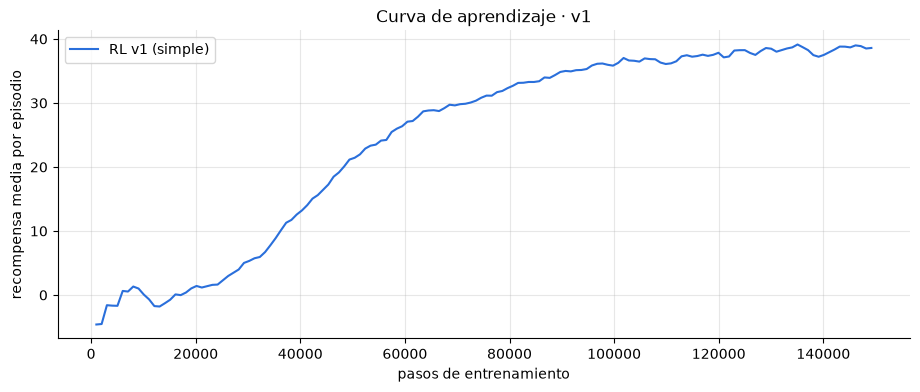

In [10]:
def curva_entrenamiento(run_id, ax, label, color):
    # Recompensa media por episodio (ventanas de 252 días) durante el entrenamiento.
    if run_id is None:
        ax.text(0.5, 0.5, "modelo reutilizado: ver la curva en MLflow", ha="center", transform=ax.transAxes)
        return
    hist = mlflow.MlflowClient().get_metric_history(run_id, "rollout/ep_rew_mean")
    ax.plot([m.step for m in hist], [m.value for m in hist], color=color, label=label)
    ax.set_xlabel("pasos de entrenamiento")
    ax.set_ylabel("recompensa media por episodio")

fig, ax = plt.subplots()
curva_entrenamiento(run_v1, ax, "RL v1 (simple)", COLORS["RL v1 (simple)"])
ax.set_title("Curva de aprendizaje · v1")
ax.legend()
fig.savefig(RESULTS / "05_curva_v1.png", dpi=150)

,retorno_acumulado_%,max_drawdown_%,costos_$,cambios_de_posicion,exposicion_media_%,sharpe_anual,valor_final_$
RL v1 (simple),-10.33,15.88,5208.13,67.0,57.17,-0.64,89667.10
Comprar y mantener,4.24,13.53,100.00,1.0,100.00,0.31,104242.28
Aleatorio (media 20 semillas),-9.17,13.80,10752.97,167.6,51.57,-0.67,90829.12


Uso de cada acción en validación: {1.0: 54.2, 0.0: 39.8, 0.5: 6.0}


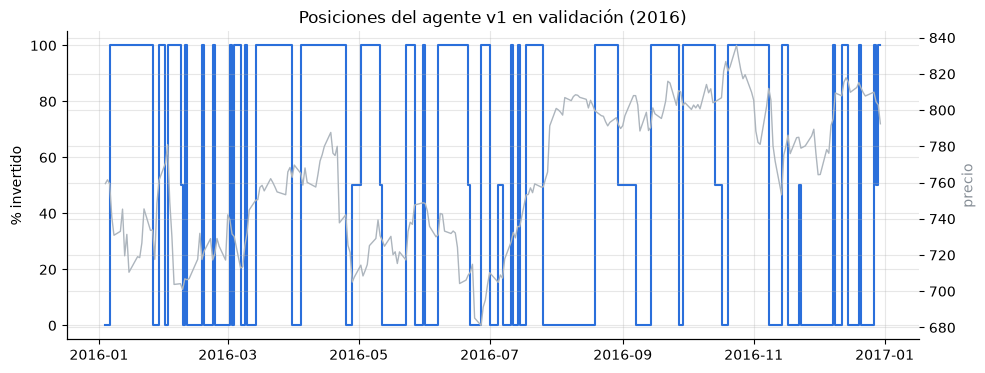

In [11]:
# Comportamiento en VALIDACIÓN (2016). El held-out sigue cerrado.
val = {"RL v1 (simple)": investor_eval.run(investor_eval.agent_policy(model_v1), "val"),
       "Comprar y mantener": investor_eval.run(investor_eval.buy_and_hold, "val")}
m_val = pd.DataFrame({k: investor_eval.metrics(v) for k, v in val.items()}).T
m_val.loc["Aleatorio (media 20 semillas)"] = investor_eval.random_summary("val")
display(m_val.round(2))

def posiciones(df, ax, title):
    ax2 = ax.twinx()
    ax2.plot(df.index, df["price"], color="#adb5bd", lw=1)
    ax2.set_ylabel("precio", color="#868e96")
    ax.step(df.index, 100 * df["position"], where="post", color="#2a6fdb")
    ax.set_ylim(-5, 105)
    ax.set_ylabel("% invertido")
    ax.set_title(title)

fig, ax = plt.subplots()
posiciones(val["RL v1 (simple)"], ax, "Posiciones del agente v1 en validación (2016)")
fig.savefig(RESULTS / "06_posiciones_v1_val.png", dpi=150)

p = val["RL v1 (simple)"]["position"].iloc[1:]
print("Uso de cada acción en validación:", (p.value_counts(normalize=True) * 100).round(1).to_dict())

**Observación del comportamiento (v1) y problemas identificados.** *(janayajoo · texto en `docs/informe/05_recompensa.md`.)*

Con la recompensa simple aparecen comportamientos típicos que debemos buscar:
- **Imitar comprar y mantener**: si el agente casi siempre elige 100 %, la recompensa simple lo empuja a ello porque el activo subió casi todo el tiempo de entrenamiento. No es un error, pero entonces "aprender" no agrega nada.
- **Rotación excesiva**: si cambia de posición muchas veces, los costos se comen la ganancia. Mirar `cambios_de_posicion` y `costos_$`.
- **Indiferencia al riesgo**: el retorno simple trata igual una ganancia de +1 % en un día tranquilo que en uno turbulento, y no penaliza las caídas largas. Mirar `max_drawdown_%` frente a comprar y mantener.

Por eso la versión 2 cambia dos cosas: usa el retorno **logarítmico** (suma de recompensas = log del crecimiento total del capital, así el agente optimiza exactamente el retorno acumulado) y **penaliza el aumento del drawdown**, para que el agente prefiera trayectorias con caídas menores.

## 6. Recompensa · versión 2: retorno log con penalización de drawdown
$$r_t = \left[\log\frac{V_{t+1}}{V_t} - \lambda \cdot \max\left(0,\ DD_{t+1} - DD_t\right)\right]\times 100,\qquad DD_t = 1 - \frac{V_t}{\max_{s\le t} V_s},\quad \lambda = 1$$
- La penalización solo actúa cuando la caída **se profundiza**; recuperarse no se castiga.
- Con $\lambda=1$, perder un 1 % adicional desde el máximo "duele" el doble que en la v1.
- Mismos hiperparámetros, misma semilla y mismos datos que la v1: la única diferencia es la recompensa.

Using cpu device
Wrapping the env in a DummyVecEnv.
Device: cpu
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 252      |
|    ep_rew_mean      | -70.6    |
|    exploration_rate | 0.979    |
| time/               |          |
|    episodes         | 4        |
|    fps              | 20141    |
|    time_elapsed     | 0        |
|    total_timesteps  | 1008     |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 252      |
|    ep_rew_mean      | -68.2    |
|    exploration_rate | 0.957    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 17417    |
|    time_elapsed     | 0        |
|    total_timesteps  | 2016     |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 0.736    |
|    n_updates        | 3        |
----------------------------------
--------------------------

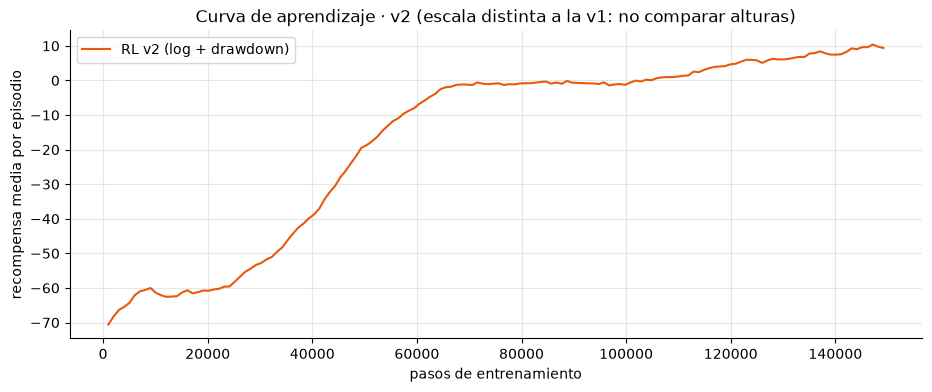

In [12]:
cfg_v2, model_v2, run_v2 = entrenar("configs/investor_dqn_log_dd.yaml")

fig, ax = plt.subplots()
curva_entrenamiento(run_v2, ax, "RL v2 (log + drawdown)", COLORS["RL v2 (log + drawdown)"])
ax.set_title("Curva de aprendizaje · v2 (escala distinta a la v1: no comparar alturas)")
ax.legend()
fig.savefig(RESULTS / "07_curva_v2.png", dpi=150)

,retorno_acumulado_%,max_drawdown_%,costos_$,cambios_de_posicion,exposicion_media_%,sharpe_anual,valor_final_$
RL v1 (simple),-10.33,15.88,5208.13,67.0,57.17,-0.64,89667.10
Comprar y mantener,4.24,13.53,100.00,1.0,100.00,0.31,104242.28
Aleatorio (media 20 semillas),-9.17,13.80,10752.97,167.6,51.57,-0.67,90829.12
RL v2 (log + drawdown),8.99,8.61,3096.82,32.0,19.32,1.02,108991.75


RL v1 (simple) → uso de acciones %: {1.0: 54.2, 0.0: 39.8, 0.5: 6.0}
RL v2 (log + drawdown) → uso de acciones %: {0.0: 79.7, 1.0: 18.3, 0.5: 2.0}


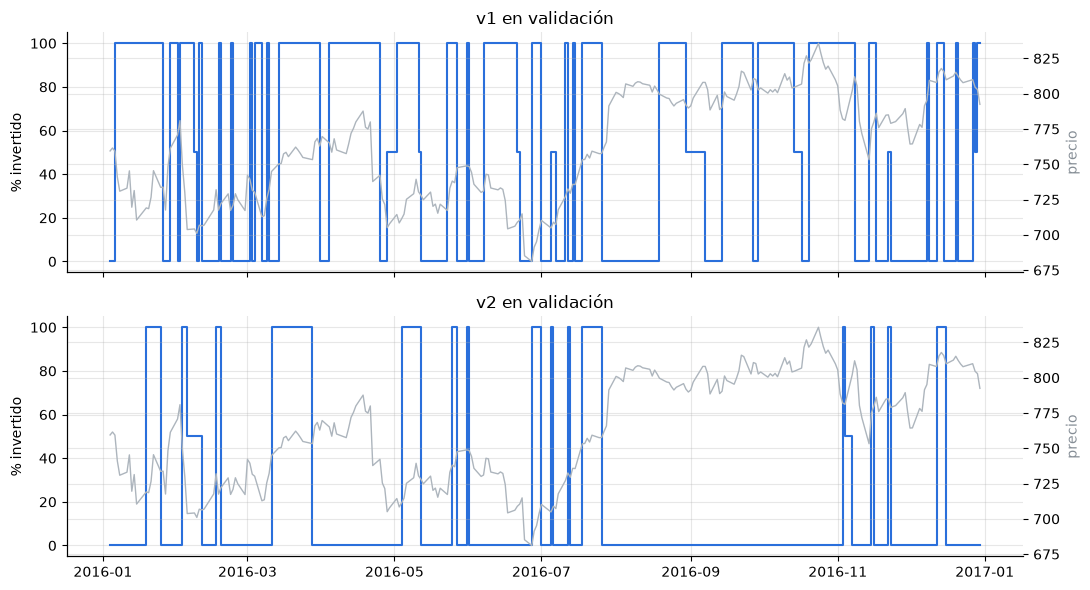

In [13]:
val["RL v2 (log + drawdown)"] = investor_eval.run(investor_eval.agent_policy(model_v2), "val")
m_val.loc["RL v2 (log + drawdown)"] = investor_eval.metrics(val["RL v2 (log + drawdown)"])
display(m_val.round(2))

fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
posiciones(val["RL v1 (simple)"], ax[0], "v1 en validación")
posiciones(val["RL v2 (log + drawdown)"], ax[1], "v2 en validación")
fig.tight_layout()
fig.savefig(RESULTS / "08_posiciones_v1_v2_val.png", dpi=150)

for k in ("RL v1 (simple)", "RL v2 (log + drawdown)"):
    p = val[k]["position"].iloc[1:]
    print(k, "→ uso de acciones %:", (p.value_counts(normalize=True) * 100).round(1).to_dict())

In [14]:
# Selección de la versión final: SOLO con validación, antes de abrir el held-out.
# Criterio: mejor retorno acumulado por unidad de drawdown (ratio de Calmar simple).
calmar = m_val["retorno_acumulado_%"] / m_val["max_drawdown_%"].clip(lower=0.1)
candidatas = calmar.loc[["RL v1 (simple)", "RL v2 (log + drawdown)"]]
FINAL = candidatas.idxmax()
print(calmar.round(2).to_string())
print("\nVersión elegida para el held-out:", FINAL)

RL v1 (simple)                  -0.65
Comprar y mantener               0.31
Aleatorio (media 20 semillas)   -0.66
RL v2 (log + drawdown)           1.04

Versión elegida para el held-out: RL v2 (log + drawdown)


**Comparación de las recompensas.** *(janayajoo · texto en `docs/informe/05_recompensa.md`.)* Responder con base en las tablas y gráficas de validación:
1. ¿Qué versión opera más? ¿Cuál paga más costos?
2. ¿La penalización de drawdown redujo la máxima caída? ¿A cambio de cuánto retorno?
3. ¿Alguna de las dos se quedó "pegada" en una sola acción? Si es así, ¿por qué la recompensa la llevó ahí?
4. ¿Cuál elegimos y por qué? (lo decide la celda anterior, antes de mirar el held-out)

## 7. Algoritmo e hiperparámetros
**DQN** (Stable-Baselines3): red Q con *replay buffer*, red objetivo y exploración ε-greedy. Es el algoritmo recomendado porque el espacio de acciones es discreto.

In [15]:
hp = cfg_v1.hyperparams
tabla_hp = pd.Series({
    "algoritmo": "DQN (Stable-Baselines3)",
    "red (MLP)": f"{8} → {hp['policy_kwargs']['net_arch']} → {len(ACTIONS)} (ReLU)",
    "learning rate": hp["learning_rate"],
    "batch size": hp["batch_size"],
    "factor de descuento γ": hp["gamma"],
    "pasos de entrenamiento": f"{cfg_v1.timesteps:,} (≈ {cfg_v1.timesteps // 252} episodios de 252 días)",
    "replay buffer": f"{hp['buffer_size']:,}",
    "pasos antes de aprender": f"{hp['learning_starts']:,}",
    "frecuencia de entrenamiento": f"cada {hp['train_freq']} pasos",
    "actualización red objetivo": f"cada {hp['target_update_interval']:,} pasos",
    "exploración": f"ε-greedy lineal de {hp['exploration_initial_eps']} a {hp['exploration_final_eps']} "
                   f"en el {hp['exploration_fraction']:.0%} inicial",
    "criterio de parada": "número fijo de pasos (sin early stopping sobre el held-out)",
    "semilla": hp["seed"],
    "costo por operar": "0,1 % del monto negociado",
})
tabla_hp.to_frame("valor")

,valor
algoritmo,DQN (Stable-Baselines3)
red (MLP),"8 → [64, 64] → 3 (ReLU)"
learning rate,0.0001
batch size,64
factor de descuento γ,0.99
pasos de entrenamiento,"150,000 (≈ 595 episodios de 252 días)"
replay buffer,"50,000"
pasos antes de aprender,"2,000"
frecuencia de entrenamiento,cada 4 pasos
actualización red objetivo,"cada 1,000 pasos"


In [16]:
# Búsqueda opcional de hiperparámetros con Optuna. Cada trial entrena en 2009-2015 y se
# califica en VALIDACIÓN (2016). Nunca usa el held-out.
if RUN_TUNE:
    study = experiments.tune(config.load("configs/investor_dqn_log_dd.yaml"))
    print("Mejores valores:", study.best_params)
    # Para usarlos: copiarlos en hyperparams del YAML y volver a correr con RETRAIN = True.
else:
    print("RUN_TUNE = False: se usan los hiperparámetros del YAML.")

RUN_TUNE = False: se usan los hiperparámetros del YAML.


## 8. Evaluación en datos no vistos (held-out 2017 – 2018)
A partir de aquí **no se cambia nada**: ni recompensa, ni hiperparámetros, ni arquitectura. Todas las estrategias corren en el mismo entorno, con el mismo costo (0,1 %) y el mismo capital inicial (\$100.000).

In [17]:
test = {
    "RL v1 (simple)": investor_eval.run(investor_eval.agent_policy(model_v1), "test"),
    "RL v2 (log + drawdown)": investor_eval.run(investor_eval.agent_policy(model_v2), "test"),
    "Comprar y mantener": investor_eval.run(investor_eval.buy_and_hold, "test"),
    "Aleatorio": investor_eval.run(investor_eval.random_policy(SEED), "test"),
}
m_test = pd.DataFrame({k: investor_eval.metrics(v) for k, v in test.items()}).T
m_test.loc["Aleatorio (media 20 semillas)"] = investor_eval.random_summary("test")
m_test.to_csv(RESULTS / "metricas_heldout.csv")
print("Versión elegida en validación:", FINAL)
m_test.round(2)

Versión elegida en validación: RL v2 (log + drawdown)


,retorno_acumulado_%,max_drawdown_%,costos_$,cambios_de_posicion,exposicion_media_%,sharpe_anual,valor_final_$
RL v1 (simple),31.99,16.57,10540.04,94.00,61.39,1.21,131991.71
RL v2 (log + drawdown),3.46,13.87,5449.30,68.00,17.99,0.26,103463.78
Comprar y mantener,56.36,15.36,100.00,1.00,100.00,1.45,156357.64
Aleatorio,31.51,8.09,22123.81,278.00,49.40,1.32,131514.85
Aleatorio (media 20 semillas),4.95,14.72,19101.50,278.35,51.12,0.27,104947.61


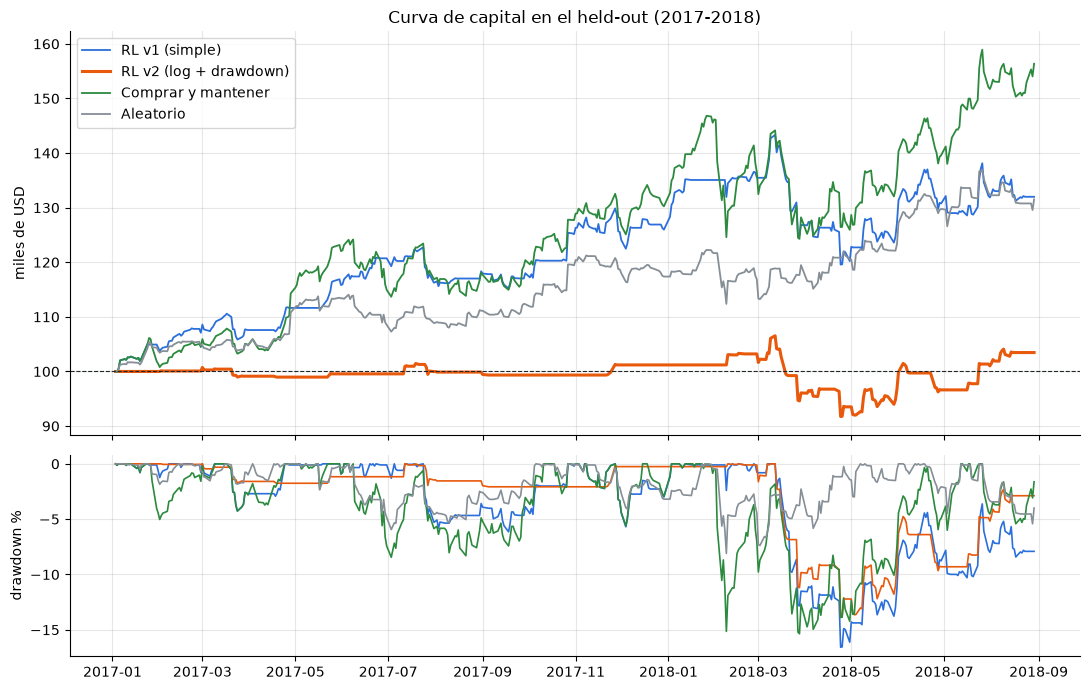

In [18]:
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for k, df in test.items():
    ax[0].plot(df.index, df["value"] / 1000, label=k, color=COLORS[k], lw=2.2 if k == FINAL else 1.3)
    dd_k = 100 * (1 - df["value"] / df["value"].cummax())
    ax[1].plot(df.index, -dd_k, color=COLORS[k], lw=1.2)
ax[0].axhline(100, color="#212529", lw=0.8, ls="--")
ax[0].set_ylabel("miles de USD")
ax[0].set_title("Curva de capital en el held-out (2017-2018)")
ax[0].legend()
ax[1].set_ylabel("drawdown %")
fig.tight_layout()
fig.savefig(RESULTS / "09_curva_capital_heldout.png", dpi=150)

RL v2 (log + drawdown): retorno 3.5 % vs comprar y mantener 56.4 % vs aleatorio 4.9 %
Máximo drawdown: 13.9 % vs 15.4 % vs 14.7 %
Costos: $5,449 vs $100 vs $19,102
¿Supera a comprar y mantener en retorno? False
¿Tiene menor drawdown que comprar y mantener? True
¿Supera al aleatorio en retorno? False


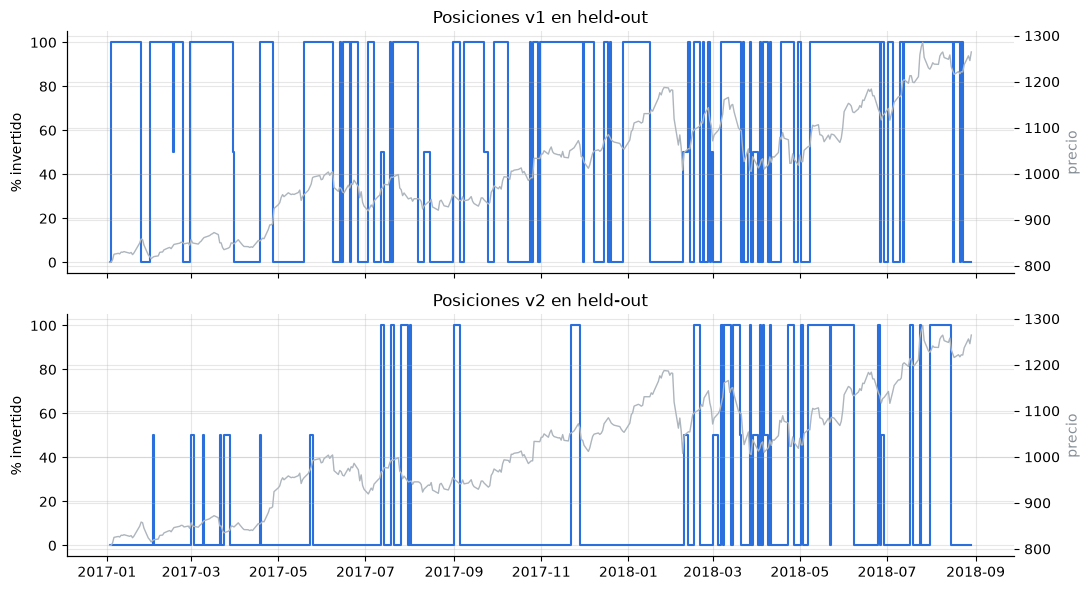

In [19]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
posiciones(test["RL v1 (simple)"], ax[0], "Posiciones v1 en held-out")
posiciones(test["RL v2 (log + drawdown)"], ax[1], "Posiciones v2 en held-out")
fig.tight_layout()
fig.savefig(RESULTS / "10_posiciones_heldout.png", dpi=150)

# Lectura automática de la tabla para apoyar la interpretación
f, bh = m_test.loc[FINAL], m_test.loc["Comprar y mantener"]
ra = m_test.loc["Aleatorio (media 20 semillas)"]
print(f"{FINAL}: retorno {f['retorno_acumulado_%']:.1f} % vs comprar y mantener {bh['retorno_acumulado_%']:.1f} % "
      f"vs aleatorio {ra['retorno_acumulado_%']:.1f} %")
print(f"Máximo drawdown: {f['max_drawdown_%']:.1f} % vs {bh['max_drawdown_%']:.1f} % vs {ra['max_drawdown_%']:.1f} %")
print(f"Costos: ${f['costos_$']:,.0f} vs ${bh['costos_$']:,.0f} vs ${ra['costos_$']:,.0f}")
print("¿Supera a comprar y mantener en retorno?", f["retorno_acumulado_%"] > bh["retorno_acumulado_%"])
print("¿Tiene menor drawdown que comprar y mantener?", f["max_drawdown_%"] < bh["max_drawdown_%"])
print("¿Supera al aleatorio en retorno?", f["retorno_acumulado_%"] > ra["retorno_acumulado_%"])

**Interpretación del held-out.** *(Lorena · texto en `docs/informe/07_evaluacion.md`.)* Con base en la tabla y la lectura automática:
- **Retorno acumulado:** ¿el agente elegido supera a comprar y mantener y al aleatorio? Si no, ¿por cuánto queda atrás y en qué tramos se pierde la diferencia (mirar la curva de capital)?
- **Máximo drawdown:** ¿el agente tuvo caídas más pequeñas? Un agente con menos retorno pero mucho menos drawdown puede ser una estrategia razonable para un inversionista adverso al riesgo.
- **Costos:** ¿cuánto se fue en operar? Comparar con la diferencia de retorno frente a comprar y mantener.
- **Posiciones:** ¿el agente se salió del mercado antes de caídas reales o en momentos aleatorios?
- **Respuesta a la pregunta central**, de forma honesta. Un resultado negativo bien explicado también responde la pregunta.

## 9. Comportamiento inesperado o fallo del agente
Buscamos automáticamente el tramo de 30 días hábiles donde el agente elegido más se separó de comprar y mantener, y lo miramos de cerca.

Peor tramo frente a comprar y mantener: 2017-04-13 → 2017-05-26 (-16.3 puntos log)
Precio del activo en el tramo: +18.2 %
Exposición media del agente en el tramo: 5 %
Cambios de posición en el tramo: 4
Idas y vueltas (A→B→A en 3 días): 21


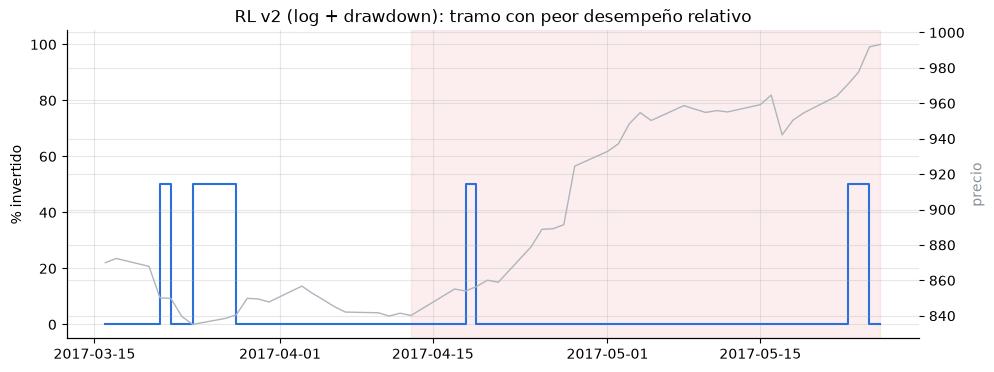

In [20]:
agente, ref = test[FINAL], test["Comprar y mantener"]
brecha = (np.log(agente["value"]).diff(30) - np.log(ref["value"]).diff(30)).dropna()
peor_fin = brecha.idxmin()
ini = agente.index[agente.index.get_loc(peor_fin) - 30]
tramo = agente.loc[ini:peor_fin]
print(f"Peor tramo frente a comprar y mantener: {ini.date()} → {peor_fin.date()} "
      f"({100 * brecha.min():.1f} puntos log)")
print(f"Precio del activo en el tramo: {100 * (tramo['price'].iloc[-1] / tramo['price'].iloc[0] - 1):+.1f} %")
print(f"Exposición media del agente en el tramo: {100 * tramo['position'].mean():.0f} %")
print(f"Cambios de posición en el tramo: {(tramo['position'].diff() != 0).sum() - 1}")

fig, ax = plt.subplots()
posiciones(agente.loc[agente.index[max(0, agente.index.get_loc(ini) - 20)]:peor_fin], ax,
           f"{FINAL}: tramo con peor desempeño relativo")
ax.axvspan(ini, peor_fin, color="#e03131", alpha=0.08)
fig.savefig(RESULTS / "11_anomalia.png", dpi=150)

# Otro diagnóstico: cuántas veces cambia de decisión dos días seguidos (ida y vuelta)
pos = agente["position"].iloc[1:].to_numpy()
idas_vueltas = int(np.sum((pos[2:] == pos[:-2]) & (pos[1:-1] != pos[:-2])))
print("Idas y vueltas (A→B→A en 3 días):", idas_vueltas)

**Análisis de la anomalía.** *(Lorena · texto en `docs/informe/08_anomalia.md`.)* Describir qué hizo el agente en ese tramo (¿se salió durante una subida? ¿se quedó invertido en una caída? ¿cambió de idea muchas veces?), qué parte del estado pudo llevarlo a esa decisión y si es una consecuencia de la recompensa (*reward hacking*), de la no-estacionariedad o simplemente de ruido.

In [21]:
# Robustez opcional: misma configuración final con otras semillas (solo validación).
if RUN_SEEDS:
    base = config.load("configs/investor_dqn_log_dd.yaml" if "v2" in FINAL else "configs/investor_dqn_simple.yaml")
    filas = {}
    for s in (1, 7, 123):
        base.hyperparams["seed"] = s
        m = registry.create(base.algo, base.env, **{**base.hyperparams, "verbose": 0})
        m.learn(total_timesteps=base.timesteps)
        filas[f"semilla {s}"] = investor_eval.metrics(investor_eval.run(investor_eval.agent_policy(m), "val"))
    display(pd.DataFrame(filas).T.round(2))
else:
    print("RUN_SEEDS = False")

RUN_SEEDS = False


## 10. Discusión y limitaciones
**Reward hacking.** Con la recompensa simple, la forma más fácil de maximizar el retorno en un mercado alcista es quedarse invertido siempre: el agente "gana" sin aprender nada sobre el mercado. Con la penalización de drawdown aparece el riesgo opuesto: salirse del mercado reduce la penalización a cero y puede volverse atractivo aunque se pierdan subidas. En ambos casos el agente optimiza lo que le pedimos, no lo que queríamos. Por eso reportamos siempre retorno **y** drawdown **y** costos, no solo la recompensa.

**No-estacionariedad.** El mercado de 2009-2015 (recuperación después de la crisis, tasas bajas) no es el de 2017-2018. Lo que funcionó en entrenamiento puede no funcionar después. Un solo activo y una sola división temporal hacen que el resultado dependa mucho de qué periodo cayó en el held-out.

**Datos escasos.** ~1.600 días de entrenamiento son muy pocos para una red neuronal. Las ventanas aleatorias de 252 días hacen que el agente vea los mismos días muchas veces: hay riesgo de memorizar el periodo de entrenamiento.

**Supuestos del simulador.**
- Ejecución al precio de cierre del mismo día en que se observa (*market on close*). En la práctica habría deslizamiento.
- Costo fijo de 0,1 %, sin spread variable ni impacto de mercado (con \$100.000 en GOOGL es razonable).
- El efectivo no gana intereses; no hay dividendos ni impuestos.
- No se permite ir en corto ni apalancarse.

**Sesgo de supervivencia.** Elegimos GOOGL, una empresa que sabemos que creció mucho. Con un activo elegido al azar el resultado podría ser muy distinto.

**Qué cambiaríamos.** Más activos y varias divisiones temporales (*walk-forward*), más semillas para medir la variabilidad del agente, y una recompensa diferencial frente a comprar y mantener para que el agente solo sea premiado por agregar valor.

## 11. Reflexión individual
Cada integrante escribe su reflexión en `docs/reflexiones/<usuario>.md`, en su propia rama y PR (así no editamos todos el mismo notebook). Las 5 preguntas del enunciado:
1. ¿Cuál fue el resultado que más le sorprendió?
2. ¿Qué decisión metodológica tuvo mayor impacto en el agente?
3. ¿Qué cambiaría si tuviera que repetir el experimento?
4. ¿Qué comportamiento del agente no logró explicar completamente?
5. ¿Cuál fue la principal diferencia entre lo aprendido en RL y su aplicación a un problema real?

Las 7 reflexiones se integran completas en el informe final y, como resumen, en esta sección del notebook.


## 12. Reproducibilidad
```bash
uv sync                                                   # instala todo desde uv.lock
uv run rlgames-sb train --config configs/investor_dqn_simple.yaml
uv run rlgames-sb train --config configs/investor_dqn_log_dd.yaml
uv run rlgames-sb tune  --config configs/investor_dqn_log_dd.yaml   # opcional
uv run mlflow ui                                          # http://127.0.0.1:5000
```
O simplemente: abrir este notebook con el kernel `.venv` y **Run All**. Semilla 42 en Python, NumPy, PyTorch, el entorno y Optuna. En CPU los resultados son reproducibles en la misma máquina; entre sistemas operativos pueden variar en decimales.

Artefactos: modelos en `saves/`, figuras y métricas en `results/`, corridas en `mlflow.db`.